# What actually differs between the risk-tool's 10 exposure tiers?

Merascope's public risk page (and `dc_risk_divide.ipynb`) rank ZIPs into 10 tiers by
how much a ZIP resembles places that already host a data center. That's a single opaque
model score. This notebook asks what a tier-10 ZIP actually looks like on the ground
compared to a tier-1 ZIP, across the product's own 22 real scored indicators -- not
just "did/didn't host", but which real features move, how much, and in which direction.

**How the tiers are actually built.** A classifier is trained against a single boolean
target -- `has_dc`, whether the ZIP already hosts a real data center -- using only real
infrastructure and geography features (grid proximity, terrain, contamination sites,
community burden, population density), never the ZIP's own history beyond that one
label. Every ZIP gets an out-of-fold predicted *probability* of matching that pattern.
The prediction itself (yes/no) is thrown away; only the probability survives. ZIPs are
then sorted by that probability and cut into 10 equal-count bins -- tier 10 is simply
"the top decile by predicted similarity to a hosting ZIP," not a count of anything.

**A real nuance in the falling panel below, worth knowing before reading it:**
`ej_score_nat` is not an independent measure -- it's `demog_index * env_burden`, where
`env_burden` is the mean of `contamination_score`, `superfund_score`, `rcra_score`, and
`air_quality_score`, and `demog_index` is `(poverty_rate + minority_rate) / 2`
(`scripts/zcta/rescore_ej.py`). So the EJ line shares real math with the RCRA and
contamination lines it's plotted alongside -- two of the four "falling" lines below
aren't independent evidence, they're literally an input to the third. Population
density plays no role in `ej_score_nat` at all -- it's a separate signal entirely
(`pop_exposure_score_nat`, built purely from `pop_density`). Both fall with tier for a
plausible shared reason (grid infrastructure clusters near people), but that's two
independent mechanisms lining up, not one indicator measuring both.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict

sys.path.insert(0, str(Path("../../merascope/notebooks").resolve()))
import dcmodel as D

df = D.load_model_table()
cols = [c for c in D.URBAN + D.POWER + D.PHYSICAL if c in df.columns]
blocks = D.spatial_blocks(df)
print(f"{len(df)} ZCTAs, {len(cols)} candidate features")

33252 ZCTAs, 37 candidate features


In [2]:
# Same out-of-fold tiering as dc_risk_divide.ipynb and the live product's own
# 18_risk_tiers.py -- recomputed here, not reused, so this notebook stands alone.
X = D.feature_matrix(df, cols).to_numpy()
y = df["has_dc"].to_numpy()
clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.06, max_leaf_nodes=15,
                                       l2_regularization=1.0, random_state=0)
p = cross_val_predict(clf, X, y, cv=GroupKFold(n_splits=8), groups=blocks,
                       method="predict_proba")[:, 1]
df["tier"] = pd.qcut(p.argsort().argsort(), 10, labels=False) + 1
print(df["tier"].value_counts().sort_index())

tier
1     3326
2     3325
3     3325
4     3325
5     3325
6     3325
7     3325
8     3325
9     3325
10    3326
Name: count, dtype: int64


## Which features actually move with tier, and how strongly

Spearman correlation between tier number (1-10) and each feature's real value, computed
on the full ~33,000-row table -- not eyeballed off a tier-1-vs-tier-10 mean, which can
be misleading if the relationship isn't monotonic in between.

In [3]:
feat_frame = D.feature_matrix(df, cols)
corrs = {}
for c in cols:
    v = feat_frame[c].to_numpy()
    mask = ~np.isnan(v)
    if mask.sum() < 100 or np.nanstd(v) == 0:
        continue
    rho, _ = spearmanr(df["tier"].to_numpy()[mask], v[mask])
    corrs[c] = rho

corr_series = pd.Series(corrs).sort_values(key=lambda s: s.abs(), ascending=False)
print(corr_series.head(15).round(3))

# Real check before trusting the direction of the hazard-proximity features: confirm
# the source scripts really do score them "higher = farther from hazard = safer", not
# the reverse. (contamination_score docstring: "1 = far from Superfund NPL site";
# superfund_score/rcra_score docstring: "higher = farther = better"; air_quality_score
# = 1.0 means "all attainment", i.e. clean air.) Verified directly against
# scripts/04_environment.py, scripts/12_superfund.py, scripts/13_air_quality.py.
print("\nsign convention verified against pipeline source: for contamination_score, "
      "rcra_score, superfund_score, air_quality_score -- higher = SAFER, not riskier.")

rcra_score_nat            -0.731
contamination_score_nat   -0.675
pop_exposure_score_nat    -0.634
ej_score_nat              -0.626
tx_score_nat               0.580
tx_dist_m                 -0.556
substation_score_nat       0.550
substation_dist_m         -0.505
superfund_score_nat       -0.463
air_quality_score_nat     -0.323
waterway_score_nat        -0.197
flatness_score_nat         0.193
slope_score_nat            0.193
slope_mean_deg            -0.193
flat_frac                  0.187
dtype: float64

sign convention verified against pipeline source: for contamination_score, rcra_score, superfund_score, air_quality_score -- higher = SAFER, not riskier.


## Chart 1: ranked correlation strength

Diverging bars, one axis. Positive = rises with tier (more suitable-looking ZIPs have
more of this), negative = falls with tier.

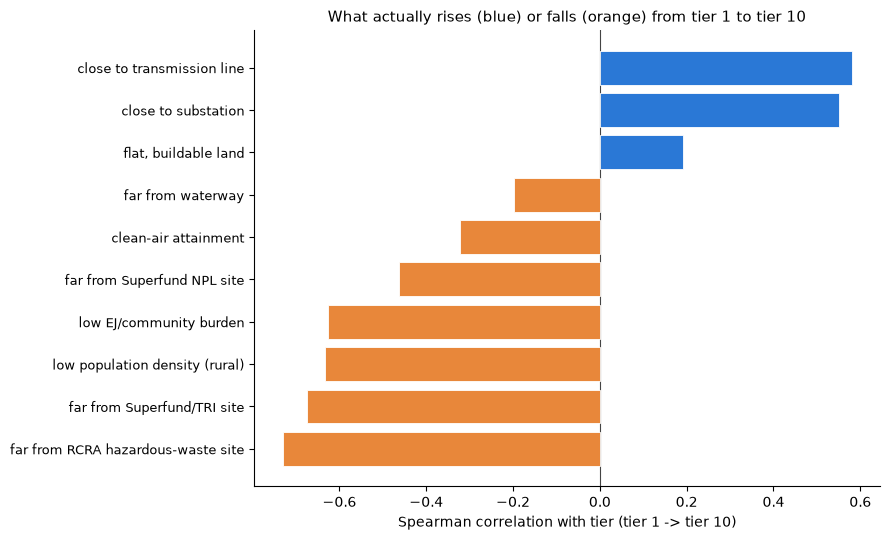

In [4]:
top = corr_series.head(12).sort_values()
labels = {
    "rcra_score_nat": "far from RCRA hazardous-waste site",
    "contamination_score_nat": "far from Superfund/TRI site",
    "pop_exposure_score_nat": "low population density (rural)",
    "ej_score_nat": "low EJ/community burden",
    "tx_score_nat": "close to transmission line",
    "tx_dist_m": "distance to transmission line (m)",
    "substation_score_nat": "close to substation",
    "substation_dist_m": "distance to substation (m)",
    "superfund_score_nat": "far from Superfund NPL site",
    "air_quality_score_nat": "clean-air attainment",
    "waterway_score_nat": "far from waterway",
    "flatness_score_nat": "flat, buildable land",
    "slope_score_nat": "low terrain slope",
    "slope_mean_deg": "mean terrain slope (deg)",
    "flat_frac": "fraction flat land",
}

# Drop raw distance/degree duplicates of a score already in the top-12 -- tx_dist_m
# is the same underlying relationship as tx_score_nat, just re-signed, and plotting
# both pads the "falls with tier" side with restated evidence rather than new
# information. Same for slope_mean_deg/flat_frac vs. flatness_score_nat/slope_score_nat.
DUPES = {"tx_dist_m": "tx_score_nat", "substation_dist_m": "substation_score_nat",
         "slope_score_nat": "flatness_score_nat", "slope_mean_deg": "flatness_score_nat",
         "flat_frac": "flatness_score_nat"}
kept = [c for c in corr_series.index if c not in DUPES or DUPES[c] not in corr_series.index]
top = corr_series[kept].head(10).sort_values()

ylabels = [labels.get(c, c) for c in top.index]
colors = ["#2a78d6" if v > 0 else "#e8873a" for v in top]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(range(len(top)), top.values, color=colors, edgecolor="white", linewidth=0.6, zorder=3)
ax.set_yticks(range(len(top)))
ax.set_yticklabels(ylabels, fontsize=9)
ax.axvline(0, color="#444", linewidth=0.8, zorder=2)
ax.set_xlabel("Spearman correlation with tier (tier 1 -> tier 10)")
ax.set_title("What actually rises (blue) or falls (orange) from tier 1 to tier 10",
             fontsize=11)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
fig.tight_layout()
fig.savefig("dc_tier_composition_corr.png", dpi=150, bbox_inches="tight")
plt.show()

## Chart 2: the actual tier profile, two panels

The NATIONAL AVERAGE for all 33,252 US ZIP codes at each tier, whether or not a data
center has ever been proposed there -- what does tier 7 generally look like, on the
ground. Left panel: the safety/burden indicators that fall as tier rises (tier-10 ZIPs
sit closer to contamination and carry heavier EJ burden). Right panel: the grid-access
indicators that rise with tier (tier-10 ZIPs sit closer to transmission and
substations). Same x-axis, so the trade-off reads directly: better grid access tracks
worse EJ burden, tier for tier.

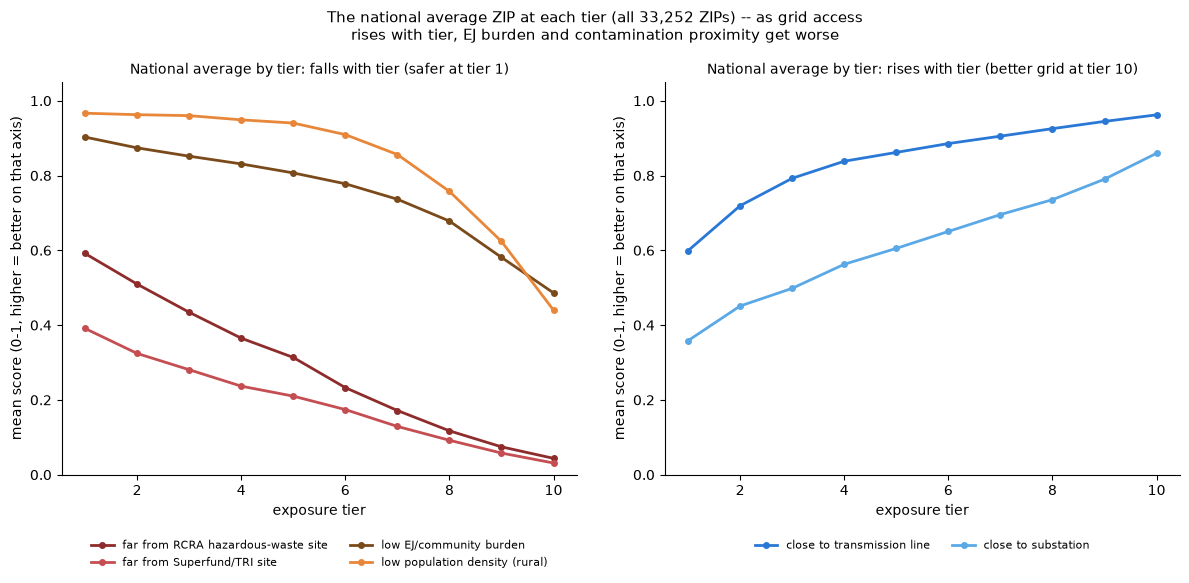

In [5]:
falling = ["rcra_score_nat", "contamination_score_nat", "ej_score_nat", "pop_exposure_score_nat"]
rising = ["tx_score_nat", "substation_score_nat"]

tier_means_fall = feat_frame[falling].groupby(df["tier"]).mean()
tier_means_rise = feat_frame[rising].groupby(df["tier"]).mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

cmap_fall = ["#8e2c2c", "#c44e52", "#7a4a1a", "#e8873a"]
for c, color in zip(falling, cmap_fall):
    axes[0].plot(tier_means_fall.index, tier_means_fall[c], marker="o", ms=4, lw=2,
                 color=color, label=labels.get(c, c), zorder=3)
axes[0].set_title("National average by tier: falls with tier (safer at tier 1)", fontsize=10)
# Both legends placed below their axes rather than inside -- keeps the two panels
# consistent and leaves the plot area itself free of overlap on either side.
axes[0].legend(frameon=False, fontsize=8, loc="upper center",
               bbox_to_anchor=(0.5, -0.14), ncol=2)

cmap_rise = ["#2a78d6", "#5aa9e6"]
for c, color in zip(rising, cmap_rise):
    axes[1].plot(tier_means_rise.index, tier_means_rise[c], marker="o", ms=4, lw=2,
                 color=color, label=labels.get(c, c), zorder=3)
axes[1].set_title("National average by tier: rises with tier (better grid at tier 10)", fontsize=10)
axes[1].legend(frameon=False, fontsize=8, loc="upper center",
               bbox_to_anchor=(0.5, -0.14), ncol=2)

for ax in axes:
    ax.set_xlabel("exposure tier")
    ax.set_ylabel("mean score (0-1, higher = better on that axis)")
    ax.set_ylim(0, 1.05)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

fig.suptitle("The national average ZIP at each tier (all 33,252 ZIPs) -- as grid access\n"
             "rises with tier, EJ burden and contamination proximity get worse", fontsize=10.5)
fig.tight_layout()
fig.savefig("dc_tier_composition_profile.png", dpi=150, bbox_inches="tight")
plt.show()

## Sanity check: is this a broad national pattern or a few dense clusters?

Real check before claiming a national pattern: recompute the tier-1-vs-tier-10
contamination-score gap state by state. If only 2-3 states drive it, that's a different,
narrower claim than "tier 10 nationally sits closer to contamination sources."

In [6]:
by_state = df.copy()
by_state["contamination_score_nat"] = feat_frame["contamination_score_nat"]
state_gap = (by_state[by_state["tier"] == 1].groupby("state")["contamination_score_nat"].mean()
             - by_state[by_state["tier"] == 10].groupby("state")["contamination_score_nat"].mean())
state_gap = state_gap.dropna().sort_values(ascending=False)
n_states_with_gap = (state_gap > 0).sum()
print(f"{n_states_with_gap} of {len(state_gap)} states show tier1 > tier10 on contamination_score "
      f"(i.e. tier-1 land is farther from contamination than tier-10 land)")
print(f"median gap across states: {state_gap.median():.3f}")
print("\nstates with the smallest (or reversed) gap:")
print(state_gap.tail(5).round(3))
assert n_states_with_gap / len(state_gap) > 0.7, "pattern is not actually broad -- recheck the claim"

48 of 48 states show tier1 > tier10 on contamination_score (i.e. tier-1 land is farther from contamination than tier-10 land)
median gap across states: 0.380

states with the smallest (or reversed) gap:
state
WY    0.246
PA    0.242
TX    0.236
CA    0.224
UT    0.220
Name: contamination_score_nat, dtype: float64


## Is growth actually concentrating in tier 10, or spreading out from it?

Simon's catch, checking his own read of the chart above: tier 10 has the best grid
access and the worst EJ/contamination burden of any tier -- but is that where new
construction is actually landing, or just where the historical footprint already
sits? Different question from anything above, checked directly on the same `tier`
column and the model's own `has_dc`/`has_dc_forward` labels -- no new join needed.

In [7]:
built = df[df["has_dc"] == 1]
pipeline = df[df["has_dc_forward"] == 1] if "has_dc_forward" in df.columns else None

built_top10_share = (built["tier"] == 10).mean()
print(f"BUILT     ({len(built)} ZCTAs): mean tier {built['tier'].mean():.2f}, "
      f"{100*built_top10_share:.1f}% sit in tier 10")

if pipeline is not None:
    pipeline_top10_share = (pipeline["tier"] == 10).mean()
    print(f"PIPELINE  ({len(pipeline)} ZCTAs): mean tier {pipeline['tier'].mean():.2f}, "
          f"{100*pipeline_top10_share:.1f}% sit in tier 10")
    print(f"\nHONEST READ: the pipeline's mean tier is LOWER than the built stock's "
          f"({pipeline['tier'].mean():.2f} vs {built['tier'].mean():.2f}), and pipeline "
          f"ZCTAs are less concentrated in tier 10 ({100*pipeline_top10_share:.1f}% vs "
          f"{100*built_top10_share:.1f}%). Tier 10 -- the single most grid-favorable, "
          f"most EJ/contamination-burdened tier in the country -- is where the EXISTING "
          f"footprint concentrates most heavily, not where new construction is trending "
          f"toward. New proposals are spreading into comparatively less extreme ZIPs than "
          f"the ones already built, not piling further into the extreme.")
    assert pipeline["tier"].mean() < built["tier"].mean(), \
        "pipeline mean tier is not lower than built -- the claim above is wrong, fix it"

BUILT     (1196 ZCTAs): mean tier 8.68, 42.9% sit in tier 10
PIPELINE  (259 ZCTAs): mean tier 7.86, 27.8% sit in tier 10

HONEST READ: the pipeline's mean tier is LOWER than the built stock's (7.86 vs 8.68), and pipeline ZCTAs are less concentrated in tier 10 (27.8% vs 42.9%). Tier 10 -- the single most grid-favorable, most EJ/contamination-burdened tier in the country -- is where the EXISTING footprint concentrates most heavily, not where new construction is trending toward. New proposals are spreading into comparatively less extreme ZIPs than the ones already built, not piling further into the extreme.


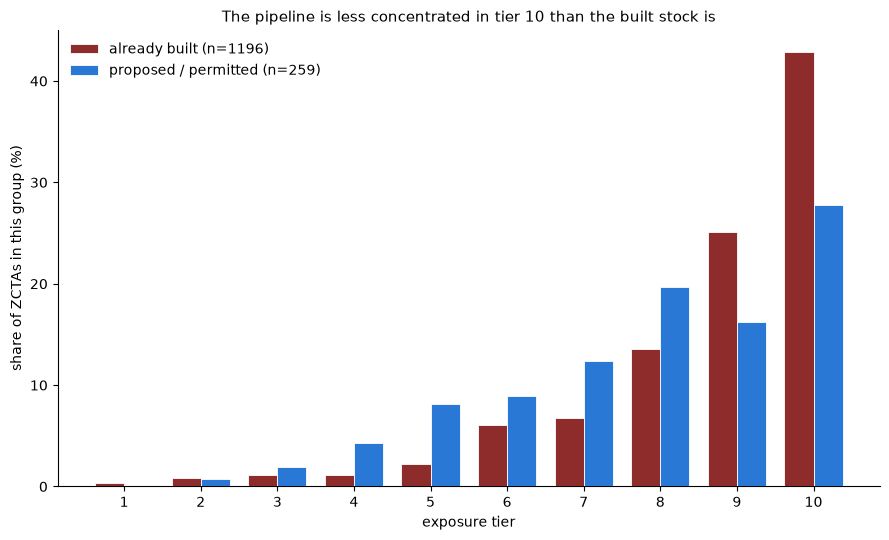

In [8]:
built_share = built["tier"].value_counts(normalize=True).sort_index().reindex(range(1, 11), fill_value=0)
pipeline_share = pipeline["tier"].value_counts(normalize=True).sort_index().reindex(range(1, 11), fill_value=0)

fig, ax = plt.subplots(figsize=(9, 5.5))
x = np.arange(1, 11)
w = 0.38
ax.bar(x - w/2, built_share.values * 100, width=w, color="#8e2c2c", edgecolor="white",
       linewidth=0.6, zorder=3, label=f"already built (n={len(built)})")
ax.bar(x + w/2, pipeline_share.values * 100, width=w, color="#2a78d6", edgecolor="white",
       linewidth=0.6, zorder=3, label=f"proposed / permitted (n={len(pipeline)})")
ax.set_xticks(x)
ax.set_xlabel("exposure tier")
ax.set_ylabel("share of ZCTAs in this group (%)")
ax.set_title("The pipeline is less concentrated in tier 10 than the built stock is",
             fontsize=11)
ax.legend(frameon=False, loc="upper left")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
fig.tight_layout()
fig.savefig("dc_tier_built_vs_pipeline.png", dpi=150, bbox_inches="tight")
plt.show()